In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
import time

# Seed sabitleme (Numaranın son 2 hanesi: 19)
SEED = 19
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
# Veri Setini Oluştur
p = np.linspace(-2, 2, 1000)
y = 1 + np.sin(np.pi * p / 4)

# Modeli Kur (Tablo 1: Lineer Aktivasyon, SGD, LR=0.1, 1 Gizli Katman, 2 Nöron)
model = keras.Sequential([
    keras.layers.Dense(2, activation='linear', input_shape=(1,), kernel_initializer='random_normal'),
    keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
])

# Modeli Derle
opt = keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

# Modeli Eğit ve Süreyi Ölç
print("Model eğitiliyor, lütfen bekleyin...")
baslangic_zamani = time.time()
history = model.fit(p, y, epochs=300, verbose=0)
bitis_zamani = time.time()
gecen_sure = bitis_zamani - baslangic_zamani

print(f"Eğitim tamamlandı! Süre: {gecen_sure:.2f} saniye")

c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model eğitiliyor, lütfen bekleyin...
Eğitim tamamlandı! Süre: 12.91 saniye


In [3]:
from sklearn.metrics import mean_squared_error, r2_score

# Eğitilen model ile tahmin yap
y_tahmin = model.predict(p)

# MSE ve R² değerlerini hesapla
mse = mean_squared_error(y, y_tahmin)
r2 = r2_score(y, y_tahmin)

print(f"Lineer Aktivasyon İçin Sonuçlar:")
print(f"MSE: {mse:.5f}")
print(f"R²: {r2:.5f}")
print(f"Süre: {gecen_sure:.2f} saniye")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Lineer Aktivasyon İçin Sonuçlar:
MSE: 0.00736
R²: 0.98529
Süre: 12.91 saniye


In [4]:
# Keras'taki aktivasyon isimleri ve tablodaki isimleri
aktivasyonlar = ['linear', 'sigmoid', 'tanh', 'relu', 'leaky_relu', 'elu', 'silu']
tablo_isimleri = ['Lineer', 'Sigmoid', 'Hiperbolik Tanjant', 'ReLU', 'LeakyReLU', 'ELU', 'SiLU']

print("Tablo 1 İçin Tüm Aktivasyon Fonksiyonları Test Ediliyor...\n")
print(f"{'Aktivasyon':<20} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 65)

# Her bir aktivasyon fonksiyonu için modeli yeniden kurup eğiten döngü
for akt, isim in zip(aktivasyonlar, tablo_isimleri):
    
    # 1. Modeli Kur
    model = keras.Sequential([
        keras.layers.Dense(2, activation=akt, input_shape=(1,), kernel_initializer='random_normal'),
        keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
    ])
    
    # 2. Modeli Derle (Sabit: SGD, LR=0.1)
    opt = keras.optimizers.SGD(learning_rate=0.1)
    model.compile(optimizer=opt, loss='mse')
    
    # 3. Modeli Eğit ve Süre Ölç
    tf.random.set_seed(19) # Her döngüde seed'i sıfırlıyoruz ki adil karşılaştırma olsun
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # 4. Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # 5. Sonuçları Ekrana Yazdır
    print(f"{isim:<20} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 1 İçin Tüm Aktivasyon Fonksiyonları Test Ediliyor...

Aktivasyon           | MSE        | R²         | Süre (sn)
-----------------------------------------------------------------


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Lineer               | 0.00736    | 0.98529    | 12.67


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Sigmoid              | 0.00010    | 0.99980    | 12.78


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (5 outputs left out)

c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ELU                  | 0.00527    | 0.98948    | 12.35


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SiLU                 | 0.00557    | 0.98886    | 13.49


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


relu aktivasyonu ile model eğitiliyor ve grafikler hazırlanıyor...


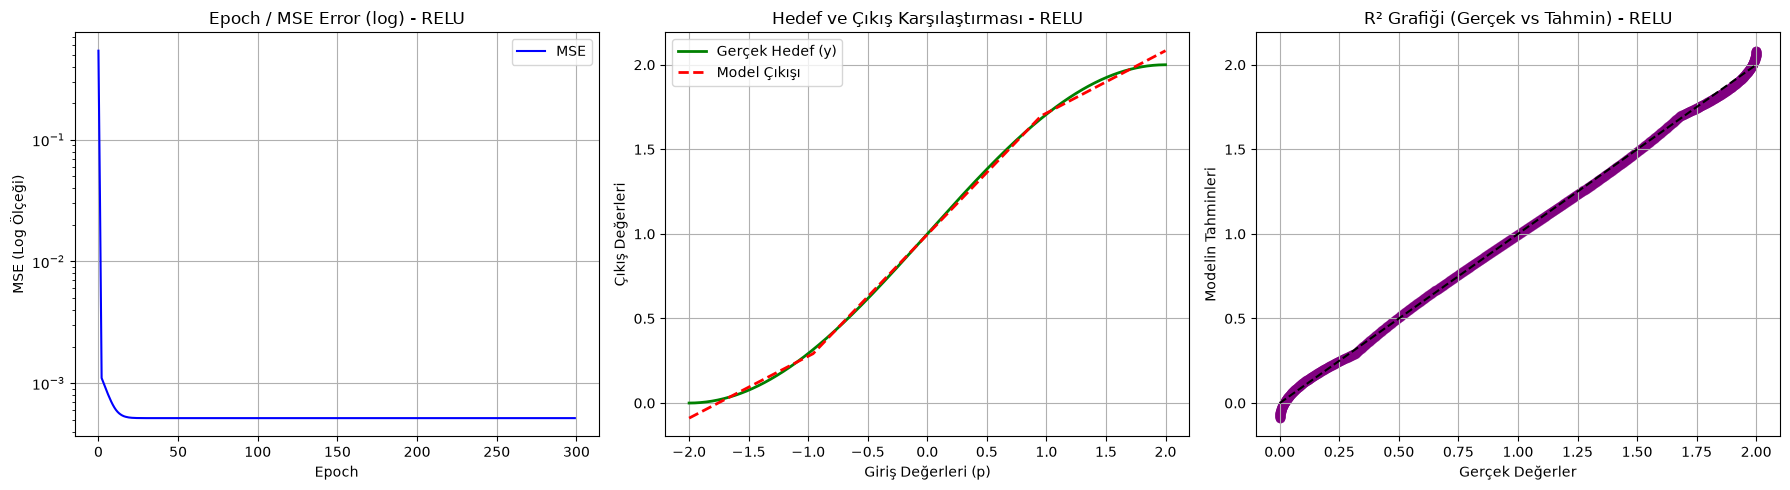

In [5]:
# KENDİ SONUCUNA GÖRE BURAYI DEĞİŞTİR:
# Tabloda en iyi çıkan aktivasyonun adını yaz ('linear', 'sigmoid', 'tanh', 'relu', 'leaky_relu', 'elu', 'silu')
sigmoid = 'relu' 

# Modeli en iyi aktivasyonla tekrar kur ve grafikleri çizdirmek için 'history' kaydını al
tf.random.set_seed(19)
np.random.seed(19)

model_en_iyi = keras.Sequential([
    keras.layers.Dense(2, activation=sigmoid, input_shape=(1,), kernel_initializer='random_normal'),
    keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
])

opt = keras.optimizers.SGD(learning_rate=0.1)
model_en_iyi.compile(optimizer=opt, loss='mse')

print(f"{sigmoid} aktivasyonu ile model eğitiliyor ve grafikler hazırlanıyor...")
# verbose=0 ile ekrana yazı basmadan eğit, ama history'i kaydet
history = model_en_iyi.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi.predict(p, verbose=0)

# 3 GRAFİĞİ YAN YANA ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log') # Ödevde istendiği gibi Y ekseni logaritmik
plt.title(f'Epoch / MSE Error (log) - {sigmoid.upper()}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - {sigmoid.upper()}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--') # Kusursuz tahmin çizgisi
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - {sigmoid.upper()}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Keras'taki aktivasyon isimleri ve tablodaki isimleri
aktivasyonlar = ['linear', 'sigmoid', 'tanh', 'relu', 'leaky_relu', 'elu', 'silu']
tablo_isimleri = ['Lineer', 'Sigmoid', 'Hiperbolik Tanjant', 'ReLU', 'LeakyReLU', 'ELU', 'SiLU']

print("Tablo 1 İçin Tüm Aktivasyon Fonksiyonları Test Ediliyor (SEED=28)...\n")
print(f"{'Aktivasyon':<20} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 65)

# Her bir aktivasyon fonksiyonu için modeli yeniden kurup eğiten döngü
for akt, isim in zip(aktivasyonlar, tablo_isimleri):
    
    # Her döngüde seed'i 28 olarak sıfırlıyoruz ki adil karşılaştırma olsun
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # 1. Modeli Kur
    model = keras.Sequential([
        keras.layers.Dense(2, activation=akt, input_shape=(1,), kernel_initializer='random_normal'),
        keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
    ])
    
    # 2. Modeli Derle (Sabit: SGD, LR=0.1)
    opt = keras.optimizers.SGD(learning_rate=0.1)
    model.compile(optimizer=opt, loss='mse')
    
    # 3. Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # 4. Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # 5. Sonuçları Ekrana Yazdır
    print(f"{isim:<20} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 1 İçin Tüm Aktivasyon Fonksiyonları Test Ediliyor (SEED=28)...

Aktivasyon           | MSE        | R²         | Süre (sn)
-----------------------------------------------------------------
Lineer               | 0.00750    | 0.98501    | 12.75


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Sigmoid              | 0.00010    | 0.99981    | 12.22


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Hiperbolik Tanjant   | 0.00010    | 0.99981    | 12.25


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (3 outputs left out)

c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ELU                  | 0.00533    | 0.98936    | 18.00


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SiLU                 | 0.00603    | 0.98796    | 19.29


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


relu aktivasyonu (SEED=28) ile model eğitiliyor ve yeni grafikler hazırlanıyor...


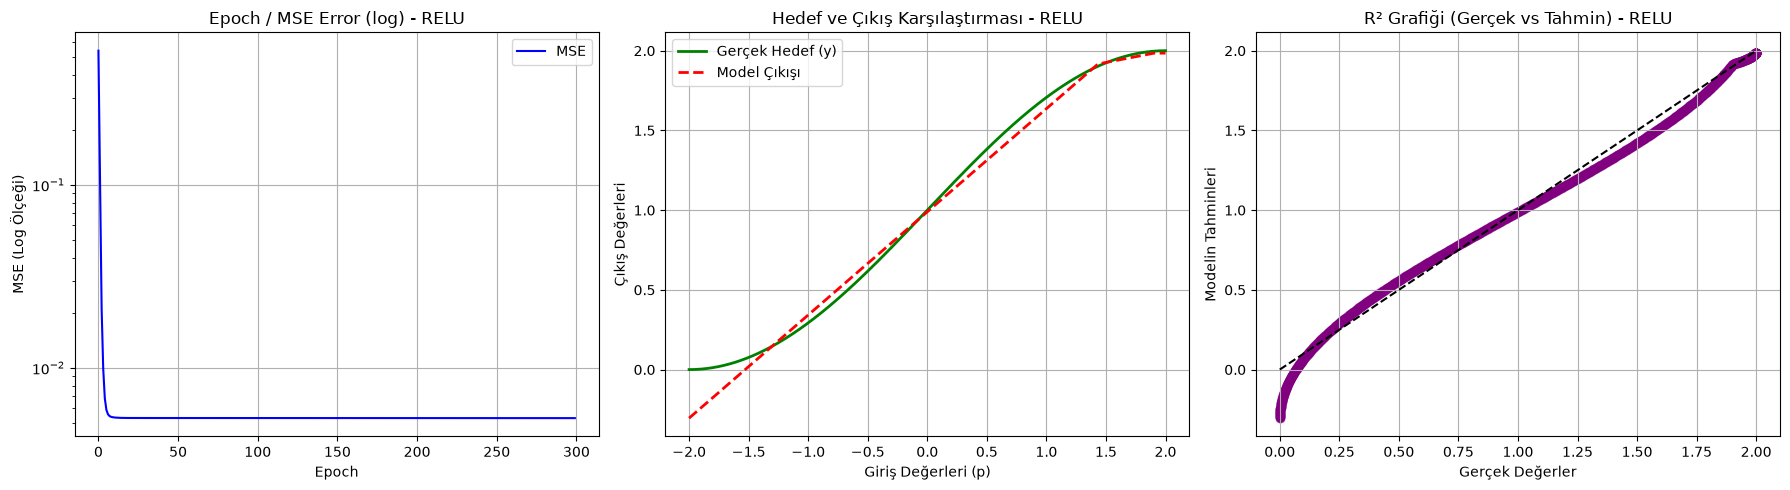

In [7]:
# KENDİ SONUCUNA GÖRE BURAYI DEĞİŞTİR:
# Tablo 1'deki en iyi aktivasyonun adını yaz ('linear', 'sigmoid', 'tanh', 'relu', 'leaky_relu', 'elu', 'silu')
sigmoid= 'relu' 

# Seed değerleri numaranın son iki hanesi olan 28'e göre güncellendi
tf.random.set_seed(28)
np.random.seed(28)

model_en_iyi = keras.Sequential([
    keras.layers.Dense(2, activation=sigmoid, input_shape=(1,), kernel_initializer='random_normal'),
    keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
])

opt = keras.optimizers.SGD(learning_rate=0.1)
model_en_iyi.compile(optimizer=opt, loss='mse')

print(f"{sigmoid} aktivasyonu (SEED=28) ile model eğitiliyor ve yeni grafikler hazırlanıyor...")
history = model_en_iyi.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi.predict(p, verbose=0)

# 3 GRAFİĞİ YAN YANA ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title(f'Epoch / MSE Error (log) - {sigmoid.upper()}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - {sigmoid.upper()}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - {sigmoid.upper()}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
# Tablo 1'de en iyi sonucu veren aktivasyonu buraya yaz
sigmoid = 'relu' 

ogrenme_oranlari = [0.1, 0.01, 0.001]

print(f"Tablo 2 İçin Öğrenme Oranları Test Ediliyor (Aktivasyon: {sigmoid}, SEED: 28)...\n")
print(f"{'Öğrenme Oranı':<15} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 60)

for lr in ogrenme_oranlari:
    
    # Her döngüde seed'i 28 olarak sıfırlıyoruz
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # Modeli Kur (Sabitler: 1 Katman, 2 Nöron, Normal Dağılım)
    model = keras.Sequential([
        keras.layers.Dense(2, activation=sigmoid, input_shape=(1,), kernel_initializer='random_normal'),
        keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
    ])
    
    # Modeli Derle (Değişken: Öğrenme Oranı)
    opt = keras.optimizers.SGD(learning_rate=lr)
    model.compile(optimizer=opt, loss='mse')
    
    # Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # Sonuçları Ekrana Yazdır
    print(f"{lr:<15} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 2 İçin Öğrenme Oranları Test Ediliyor (Aktivasyon: relu, SEED: 28)...

Öğrenme Oranı   | MSE        | R²         | Süre (sn)
------------------------------------------------------------


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


0.1             | 0.00529    | 0.98944    | 12.68


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


0.01            | 0.00498    | 0.99005    | 12.20


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


0.001           | 0.01546    | 0.96911    | 12.10


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Öğrenme Oranı 0.01 ile model eğitiliyor ve grafikler hazırlanıyor...


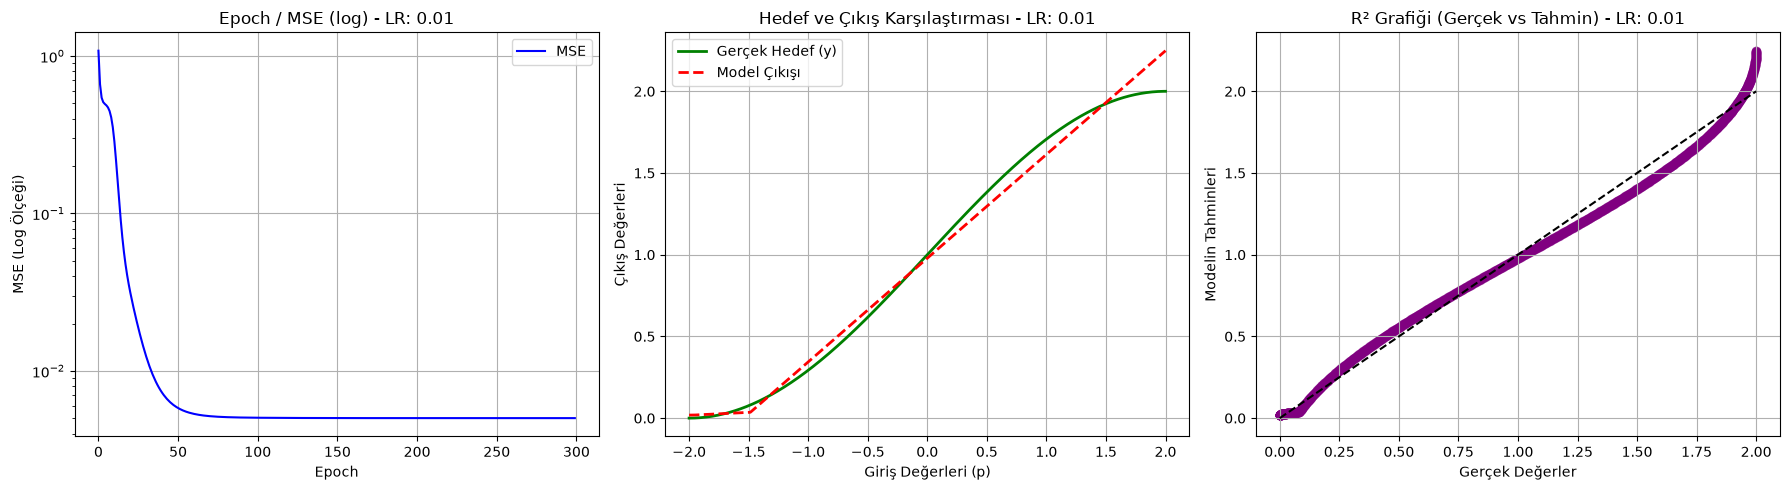

In [9]:
# Tablo 1'de en iyi sonucu veren aktivasyonu buraya yaz
sigmoid = 'relu'
en_iyi_lr = 0.01

# Seed ayarı (Okul numarasının son 2 hanesi: 28)
tf.random.set_seed(28)
np.random.seed(28)

# Modeli Kur
model_en_iyi_lr = keras.Sequential([
    keras.layers.Dense(2, activation=sigmoid, input_shape=(1,), kernel_initializer='random_normal'),
    keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
])

# Modeli Derle (En iyi öğrenme oranı olan 0.01 ile)
opt = keras.optimizers.SGD(learning_rate=en_iyi_lr)
model_en_iyi_lr.compile(optimizer=opt, loss='mse')

print(f"Öğrenme Oranı {en_iyi_lr} ile model eğitiliyor ve grafikler hazırlanıyor...")
history = model_en_iyi_lr.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi_lr.predict(p, verbose=0)

# GRAFİKLERİ ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title(f'Epoch / MSE (log) - LR: {en_iyi_lr}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - LR: {en_iyi_lr}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - LR: {en_iyi_lr}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# Önceki tablolardaki en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid' 
secilen_lr = 0.01

optimizer_isimleri = ['SGD', 'RMSProp', 'ADAM']

print("Tablo 3 İçin Ayar Yöntemleri Test Ediliyor...\n")
print(f"(Aktivasyon: {secilen_aktivasyon}, LR: {secilen_lr}, SEED: 28)\n")
print(f"{'Ayar Yöntemi':<15} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 60)

for opt_isim in optimizer_isimleri:
    
    # Her döngüde adil karşılaştırma için seed=28
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # Modeli Kur (Sabitler: 1 Katman, 2 Nöron, Normal Dağılım)
    model = keras.Sequential([
        keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer='random_normal'),
        keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
    ])
    
    # İlgili optimizatörü ayarla
    if opt_isim == 'SGD':
        opt = keras.optimizers.SGD(learning_rate=secilen_lr)
    elif opt_isim == 'RMSProp':
        opt = keras.optimizers.RMSprop(learning_rate=secilen_lr)
    elif opt_isim == 'ADAM':
        opt = keras.optimizers.Adam(learning_rate=secilen_lr)
        
    # Modeli Derle
    model.compile(optimizer=opt, loss='mse')
    
    # Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # Sonuçları Ekrana Yazdır
    print(f"{opt_isim:<15} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 3 İçin Ayar Yöntemleri Test Ediliyor...

(Aktivasyon: sigmoid, LR: 0.01, SEED: 28)

Ayar Yöntemi    | MSE        | R²         | Süre (sn)
------------------------------------------------------------
SGD             | 0.00012    | 0.99977    | 15.84


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


RMSProp         | 0.00056    | 0.99888    | 17.19


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ADAM            | 0.00003    | 0.99994    | 17.85


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


En iyi ayar yöntemi olan ADAM ile model eğitiliyor ve grafikler hazırlanıyor...


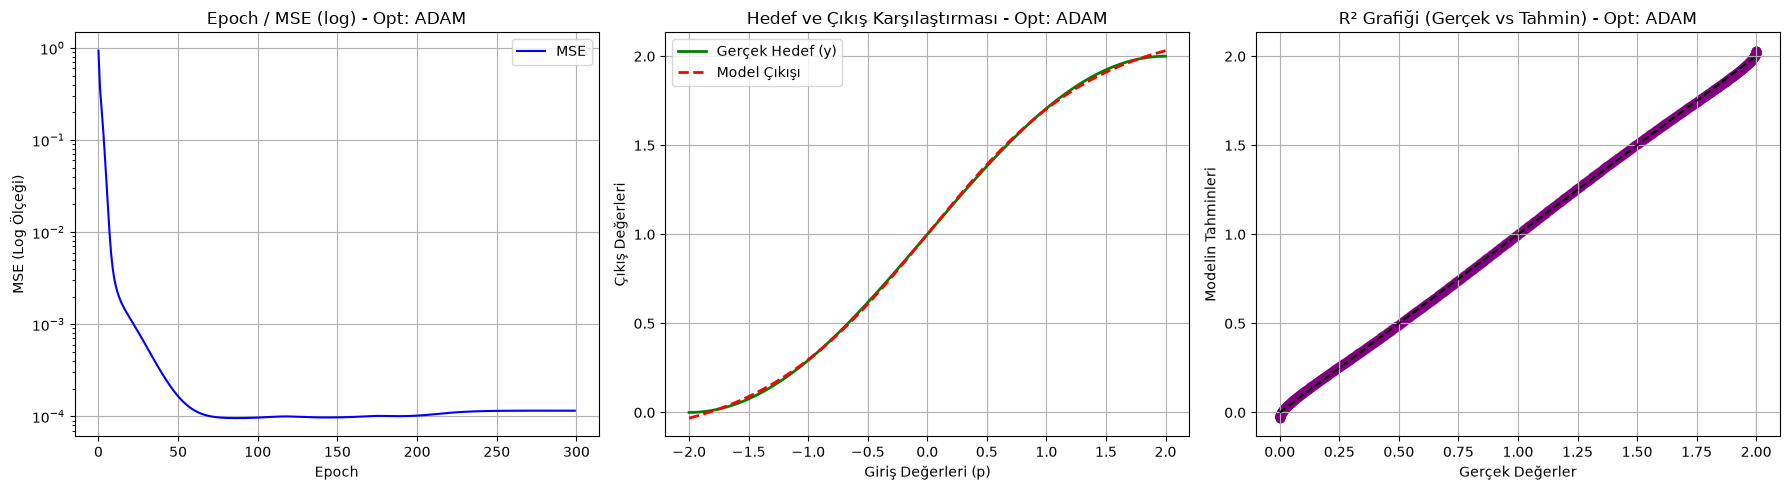

In [11]:
# Önceki tablolardan gelen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
en_iyi_lr = 0.01
en_iyi_opt_isim = 'ADAM'

# Seed ayarı (Okul numarasının son 2 hanesi: 28)
tf.random.set_seed(28)
np.random.seed(28)

# Modeli Kur
model_en_iyi_opt = keras.Sequential([
    keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer='random_normal'),
    keras.layers.Dense(1, activation='linear', kernel_initializer='random_normal')
])

# ADAM Optimizatörünü ayarla
opt = keras.optimizers.Adam(learning_rate=en_iyi_lr)
model_en_iyi_opt.compile(optimizer=opt, loss='mse')

print(f"En iyi ayar yöntemi olan {en_iyi_opt_isim} ile model eğitiliyor ve grafikler hazırlanıyor...")
history = model_en_iyi_opt.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi_opt.predict(p, verbose=0)

# GRAFİKLERİ ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title(f'Epoch / MSE (log) - Opt: {en_iyi_opt_isim}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - Opt: {en_iyi_opt_isim}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - Opt: {en_iyi_opt_isim}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
# Önceki tablolardan gelen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
secilen_lr = 0.01

dagilimlar = ['random_normal', 'random_uniform']
tablo_isimleri = ['Normal Dağılım', 'Uniform Dağılım']

print("Tablo 4 İçin Başlangıç Dağılımları Test Ediliyor...\n")
print(f"(Aktivasyon: {secilen_aktivasyon}, LR: {secilen_lr}, Opt: ADAM, SEED: 28)\n")
print(f"{'Dağılım':<20} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 65)

for dagilim, isim in zip(dagilimlar, tablo_isimleri):
    
    # Her döngüde adil karşılaştırma için seed=28
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # Modeli Kur (Değişken: kernel_initializer)
    model = keras.Sequential([
        keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=dagilim),
        keras.layers.Dense(1, activation='linear', kernel_initializer=dagilim)
    ])
    
    # Optimizatörü ve modeli derle (En iyi yöntem olan ADAM ile)
    opt = keras.optimizers.Adam(learning_rate=secilen_lr)
    model.compile(optimizer=opt, loss='mse')
    
    # Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # Sonuçları Ekrana Yazdır
    print(f"{isim:<20} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 4 İçin Başlangıç Dağılımları Test Ediliyor...

(Aktivasyon: sigmoid, LR: 0.01, Opt: ADAM, SEED: 28)

Dağılım              | MSE        | R²         | Süre (sn)
-----------------------------------------------------------------
Normal Dağılım       | 0.00003    | 0.99993    | 17.10


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Uniform Dağılım      | 0.00005    | 0.99990    | 17.64


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


En iyi başlangıç dağılımı olan Normal Dağılım ile model eğitiliyor ve grafikler hazırlanıyor...


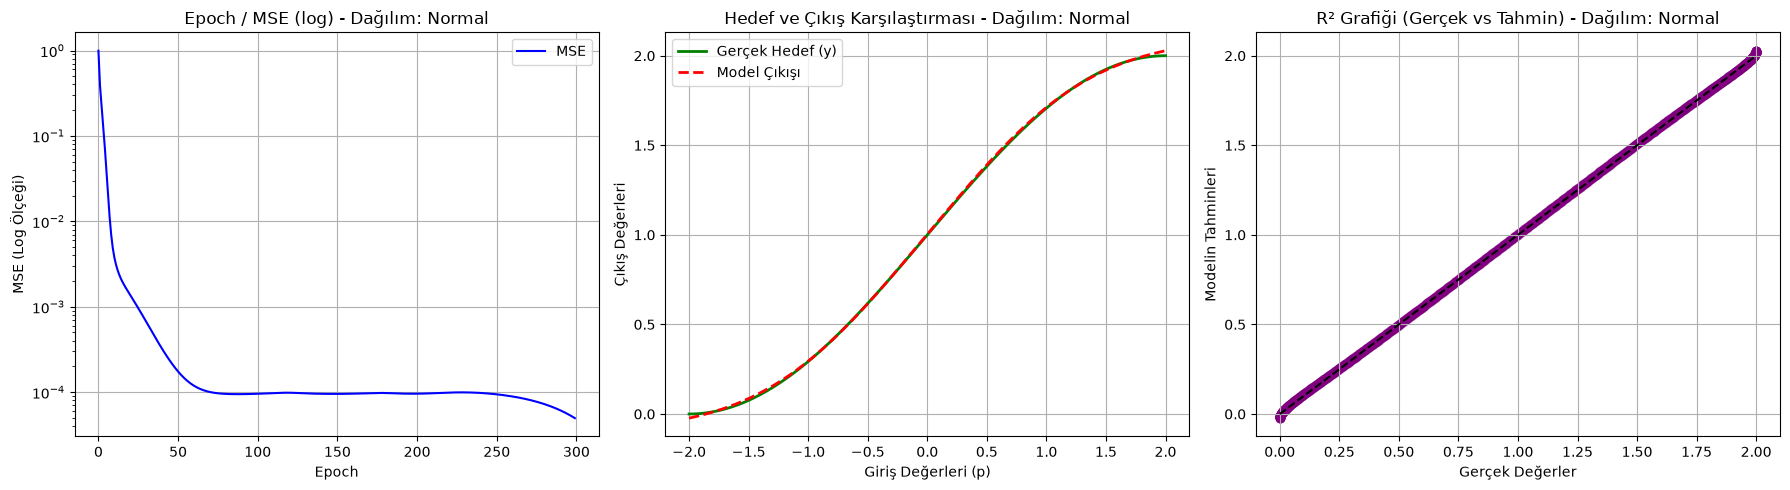

In [13]:
# Önceki tablolardan gelen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
en_iyi_lr = 0.01
en_iyi_dagilim = 'random_normal'

# Seed ayarı (Okul numarasının son 2 hanesi: 28)
tf.random.set_seed(28)
np.random.seed(28)

# Modeli Kur (En iyi dağılım olan random_normal ile)
model_en_iyi_dagilim = keras.Sequential([
    keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=en_iyi_dagilim),
    keras.layers.Dense(1, activation='linear', kernel_initializer=en_iyi_dagilim)
])

# ADAM Optimizatörünü ayarla
opt = keras.optimizers.Adam(learning_rate=en_iyi_lr)
model_en_iyi_dagilim.compile(optimizer=opt, loss='mse')

print("En iyi başlangıç dağılımı olan Normal Dağılım ile model eğitiliyor ve grafikler hazırlanıyor...")
history = model_en_iyi_dagilim.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi_dagilim.predict(p, verbose=0)

# GRAFİKLERİ ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title('Epoch / MSE (log) - Dağılım: Normal')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title('Hedef ve Çıkış Karşılaştırması - Dağılım: Normal')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title('R² Grafiği (Gerçek vs Tahmin) - Dağılım: Normal')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
# Sabitlenen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
secilen_lr = 0.01
en_iyi_dagilim = 'random_normal'

katman_sayilari = [1, 2, 5, 10, 20]

print("Tablo 5 İçin Gizli Katman Sayıları Test Ediliyor...\n")
print(f"(Aktivasyon: {secilen_aktivasyon}, LR: {secilen_lr}, Opt: ADAM, Dağılım: Normal, SEED: 28)\n")
print(f"{'Katman Sayısı':<15} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 60)

for katman in katman_sayilari:
    
    # Her döngüde adil karşılaştırma için seed=28
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # Kademeli olarak model oluşturma
    model = keras.Sequential()
    
    # 1. Gizli Katman (Input shape sadece ilk katmanda belirtilir)
    model.add(keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=en_iyi_dagilim))
    
    # Kalan Gizli Katmanları döngüyle ekle
    for _ in range(katman - 1):
        model.add(keras.layers.Dense(2, activation=secilen_aktivasyon, kernel_initializer=en_iyi_dagilim))
        
    # Çıkış Katmanı (Lineer, 1 nöron)
    model.add(keras.layers.Dense(1, activation='linear', kernel_initializer=en_iyi_dagilim))
    
    # Optimizatörü ve modeli derle
    opt = keras.optimizers.Adam(learning_rate=secilen_lr)
    model.compile(optimizer=opt, loss='mse')
    
    # Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # Sonuçları Ekrana Yazdır
    print(f"{katman:<15} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 5 İçin Gizli Katman Sayıları Test Ediliyor...

(Aktivasyon: sigmoid, LR: 0.01, Opt: ADAM, Dağılım: Normal, SEED: 28)

Katman Sayısı   | MSE        | R²         | Süre (sn)
------------------------------------------------------------
1               | 0.00002    | 0.99995    | 18.07


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2               | 0.00013    | 0.99974    | 17.99


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5               | 0.00015    | 0.99970    | 16.07


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10              | 0.50096    | -0.00093   | 16.04


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


20              | 0.50093    | -0.00086   | 19.87


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1 Gizli Katman ile model eğitiliyor ve grafikler hazırlanıyor...


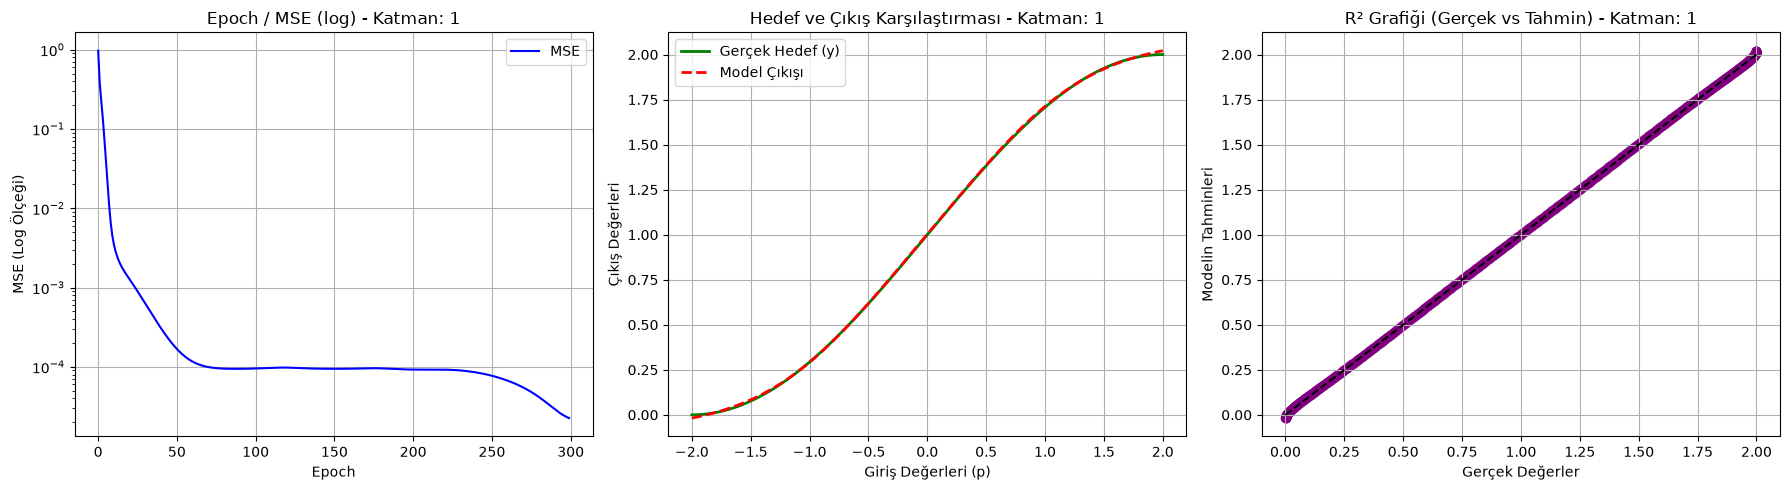

In [15]:
# Sabitlenen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
en_iyi_lr = 0.01
en_iyi_dagilim = 'random_normal'
en_iyi_katman = 1

# Seed ayarı (Okul numarasının son 2 hanesi: 28)
tf.random.set_seed(28)
np.random.seed(28)

# En iyi katman sayısı ile Modeli Kur
model_en_iyi_katman = keras.Sequential()

# İlk Gizli Katman
model_en_iyi_katman.add(keras.layers.Dense(2, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=en_iyi_dagilim))

# Eğer katman sayısı 1'den büyük olsaydı eklenecek olan ara katmanlar döngüsü
for _ in range(en_iyi_katman - 1):
    model_en_iyi_katman.add(keras.layers.Dense(2, activation=secilen_aktivasyon, kernel_initializer=en_iyi_dagilim))
    
# Çıkış Katmanı
model_en_iyi_katman.add(keras.layers.Dense(1, activation='linear', kernel_initializer=en_iyi_dagilim))

# ADAM Optimizatörünü ayarla
opt = keras.optimizers.Adam(learning_rate=en_iyi_lr)
model_en_iyi_katman.compile(optimizer=opt, loss='mse')

print(f"{en_iyi_katman} Gizli Katman ile model eğitiliyor ve grafikler hazırlanıyor...")
history = model_en_iyi_katman.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_en_iyi_katman.predict(p, verbose=0)

# GRAFİKLERİ ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title(f'Epoch / MSE (log) - Katman: {en_iyi_katman}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - Katman: {en_iyi_katman}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - Katman: {en_iyi_katman}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()

In [16]:
# Sabitlenen en iyi değerlerimiz
secilen_aktivasyon = 'sigmoid'
secilen_lr = 0.01
en_iyi_dagilim = 'random_normal'
en_iyi_katman = 1

noron_sayilari = [2, 5, 10, 20, 50]

print("Tablo 6 İçin Nöron Sayıları Test Ediliyor...\n")
print(f"(Aktivasyon: {secilen_aktivasyon}, LR: {secilen_lr}, Opt: ADAM, Dağılım: Normal, Katman: 1, SEED: 28)\n")
print(f"{'Nöron Sayısı':<15} | {'MSE':<10} | {'R²':<10} | {'Süre (sn)'}")
print("-" * 60)

for noron in noron_sayilari:
    
    # Her döngüde adil karşılaştırma için seed=28
    tf.random.set_seed(28)
    np.random.seed(28)
    
    # Modeli Kur (1 Gizli Katman, Değişken Nöron Sayısı)
    model = keras.Sequential([
        keras.layers.Dense(noron, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=en_iyi_dagilim),
        keras.layers.Dense(1, activation='linear', kernel_initializer=en_iyi_dagilim)
    ])
    
    # Optimizatörü ve modeli derle
    opt = keras.optimizers.Adam(learning_rate=secilen_lr)
    model.compile(optimizer=opt, loss='mse')
    
    # Modeli Eğit ve Süre Ölç
    baslangic = time.time()
    model.fit(p, y, epochs=300, verbose=0)
    sure = time.time() - baslangic
    
    # Tahmin Yap ve Metrikleri Hesapla
    y_tahmin = model.predict(p, verbose=0)
    mse = mean_squared_error(y, y_tahmin)
    r2 = r2_score(y, y_tahmin)
    
    # Sonuçları Ekrana Yazdır
    print(f"{noron:<15} | {mse:<10.5f} | {r2:<10.5f} | {sure:.2f}")

Tablo 6 İçin Nöron Sayıları Test Ediliyor...

(Aktivasyon: sigmoid, LR: 0.01, Opt: ADAM, Dağılım: Normal, Katman: 1, SEED: 28)

Nöron Sayısı    | MSE        | R²         | Süre (sn)
------------------------------------------------------------
2               | 0.00009    | 0.99981    | 17.53


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5               | 0.00012    | 0.99977    | 15.10


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10              | 0.00009    | 0.99982    | 12.79


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


20              | 0.00012    | 0.99975    | 12.80


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


50              | 0.00023    | 0.99953    | 12.69


c:\Users\velie\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10 Nöron ile final modeli eğitiliyor ve grafikler hazırlanıyor...


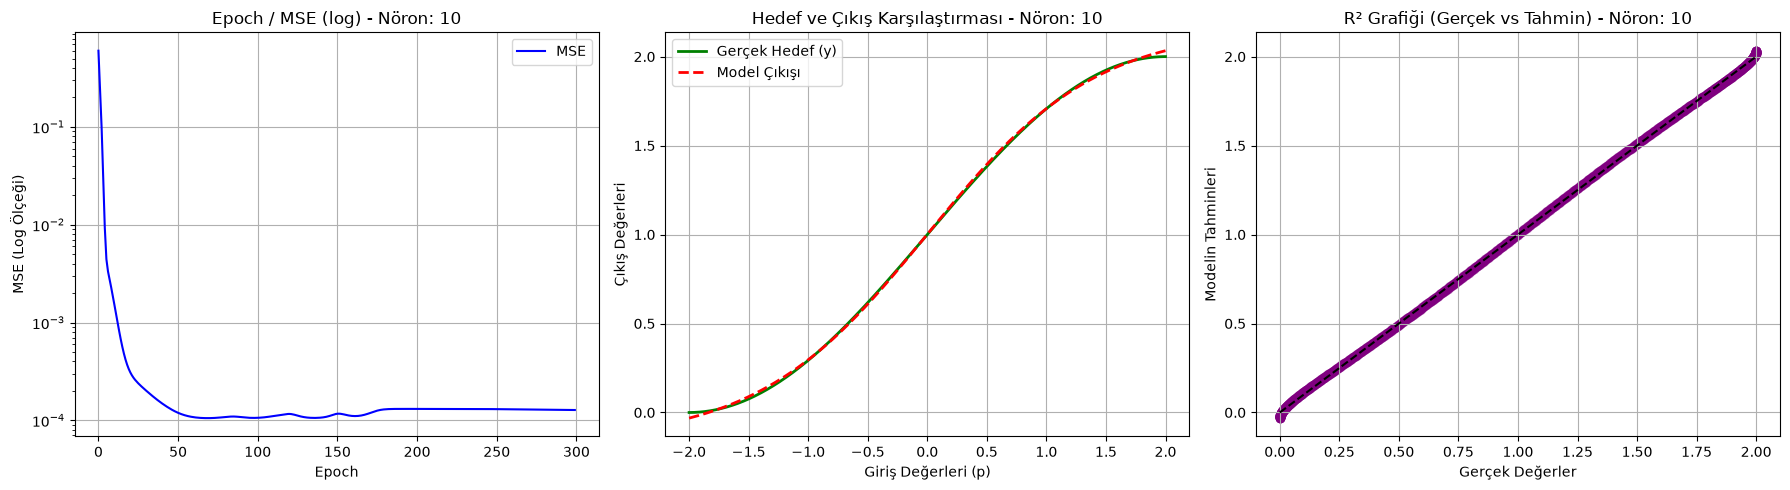

In [17]:
# Tüm deneylerin sonucunda bulduğumuz en iyi (final) değerler
secilen_aktivasyon = 'sigmoid'
en_iyi_lr = 0.01
en_iyi_dagilim = 'random_normal'
en_iyi_noron = 10

# Seed ayarı (Okul numarasının son 2 hanesi: 28)
tf.random.set_seed(28)
np.random.seed(28)

# Modeli Kur (1 Gizli Katman, 10 Nöron)
model_final = keras.Sequential([
    keras.layers.Dense(en_iyi_noron, activation=secilen_aktivasyon, input_shape=(1,), kernel_initializer=en_iyi_dagilim),
    keras.layers.Dense(1, activation='linear', kernel_initializer=en_iyi_dagilim)
])

# ADAM Optimizatörünü ayarla
opt = keras.optimizers.Adam(learning_rate=en_iyi_lr)
model_final.compile(optimizer=opt, loss='mse')

print(f"{en_iyi_noron} Nöron ile final modeli eğitiliyor ve grafikler hazırlanıyor...")
history = model_final.fit(p, y, epochs=300, verbose=0)
y_tahmin = model_final.predict(p, verbose=0)

# GRAFİKLERİ ÇİZDİRME
plt.figure(figsize=(18, 5))

# 1. Grafik: Epoch / MSE Error (log)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='MSE', color='blue')
plt.yscale('log')
plt.title(f'Epoch / MSE (log) - Nöron: {en_iyi_noron}')
plt.xlabel('Epoch')
plt.ylabel('MSE (Log Ölçeği)')
plt.grid(True)
plt.legend()

# 2. Grafik: Hedef ve Çıkış Grafiği
plt.subplot(1, 3, 2)
plt.plot(p, y, label='Gerçek Hedef (y)', color='green', linewidth=2)
plt.plot(p, y_tahmin, label='Model Çıkışı', color='red', linestyle='dashed', linewidth=2)
plt.title(f'Hedef ve Çıkış Karşılaştırması - Nöron: {en_iyi_noron}')
plt.xlabel('Giriş Değerleri (p)')
plt.ylabel('Çıkış Değerleri')
plt.grid(True)
plt.legend()

# 3. Grafik: R² Grafiği (Gerçek vs Tahmin Saçılımı)
plt.subplot(1, 3, 3)
plt.scatter(y, y_tahmin, color='purple', alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], color='black', linestyle='--')
plt.title(f'R² Grafiği (Gerçek vs Tahmin) - Nöron: {en_iyi_noron}')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Modelin Tahminleri')
plt.grid(True)

plt.tight_layout()
plt.show()